# Task 2: จำแนกกลุ่มผู้เล่น (segment) 4 คลาส

## ภาพรวมของโจทย์และ metric

โจทย์คือทำนาย `segment` ของผู้เล่นแต่ละคน ซึ่งมี 4 คลาส (0, 1, 2, 3) จากพฤติกรรมการเล่น การใช้จ่าย และกิจกรรมทางสังคม
metric ที่ใช้คือ **macro F1** (ค่าเฉลี่ยของ F1 ทั้ง 4 คลาสแบบให้น้ำหนักเท่ากัน) ดังนั้นคลาสที่มีจำนวนน้อยมีผลต่อคะแนนเท่ากับคลาสใหญ่

ภาพรวมของ pipeline สุดท้าย:

1. GBDT 3 ตัว (LightGBM, XGBoost, CatBoost) บนฟีเจอร์ดิบและฟีเจอร์ที่สร้างเพิ่ม แล้วเฉลี่ยความน่าจะเป็น
2. MLP (PyTorch) 3 seeds แล้วผสมกับค่าเฉลี่ย GBDT ด้วยน้ำหนักที่เลือกจาก OOF
3. Naive Bayes แบบ binned density ที่มีโมเดล label noise ฝึกด้วย EM
4. รวมข้อ 2 และข้อ 3 แบบ log-mix (ค่าเฉลี่ยเรขาคณิตถ่วงน้ำหนัก) แล้วปรับน้ำหนักตัดสินใจรายคลาสบน OOF

ทุกโมเดลใช้ fold ชุดเดียวกัน คือ `StratifiedKFold(5, shuffle=True, random_state=42)` คะแนนที่รายงานเป็นคะแนน out-of-fold (OOF) บนข้อมูล train ทั้งหมด
และการทำนาย test ใช้ค่าเฉลี่ยของโมเดลจาก 5 fold ทุกอย่างที่ต้อง fit (category levels, rank, median, QuantileTransformer, bin edges, น้ำหนัก) เรียนจากข้อมูล train เท่านั้น

In [1]:
import os
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, confusion_matrix

import models
from features import load_data, base_features, text_columns, gbdt_features, nn_matrices, TARGET
from models import make_folds, run_gbdt_cv, run_nn_cv
from naive_bayes import NB2, nb_features, run_nb_cv
from ensemble import macro_f1, log_mix, fit_class_weights, nested_weighted_labels

DATA = Path(os.environ.get('CPE342_DATA', '../data'))
OUT_DIR = Path('output')
OUT_DIR.mkdir(exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
models.N_THREADS = 8        # threads for LightGBM / CatBoost
models.XGB_THREADS = 16     # XGBoost hist output depends slightly on nthread; 16 matches the submitted run
NN_THREADS = 6              # threads for the PyTorch MLP (same value as the submitted run)
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': False})
T_START = time.time()

## การโหลดข้อมูล

In [2]:
train, test = load_data(DATA)
y = train[TARGET].astype(int).values
feats = base_features(train)
text_cols = text_columns(train, feats)
num_cols = [c for c in feats if c not in text_cols]
print('train', train.shape, ' test', test.shape)
print(f'{len(num_cols)} numeric features, {len(text_cols)} text features (random_metric_1..3 excluded)')
print('missing rate per column: about', round(train[feats].isna().mean().median(), 3),
      '| region', round(train['region'].isna().mean(), 3), '| payment_method', round(train['payment_method'].isna().mean(), 3))

train (104000, 46)  test (25889, 45)
31 numeric features, 10 text features (random_metric_1..3 excluded)
missing rate per column: about 0.077 | region 0.262 | payment_method 0.308


## การสำรวจข้อมูลที่เกี่ยวกับการเลือกวิธี

### สัดส่วนของคลาส

คลาสไม่สมดุลปานกลาง (คลาส 0 มากที่สุด คลาส 3 น้อยที่สุด) เพราะ metric เป็น macro F1 การทำนายด้วย argmax ของความน่าจะเป็นอย่างเดียวจะเอนไปทางคลาสใหญ่
จึงมีขั้นตอนปรับน้ำหนักรายคลาสในตอนท้าย

segment,0,1,2,3
count,40957.000,26032.00,21029.000,15982.000
share,0.394,0.25,0.202,0.154


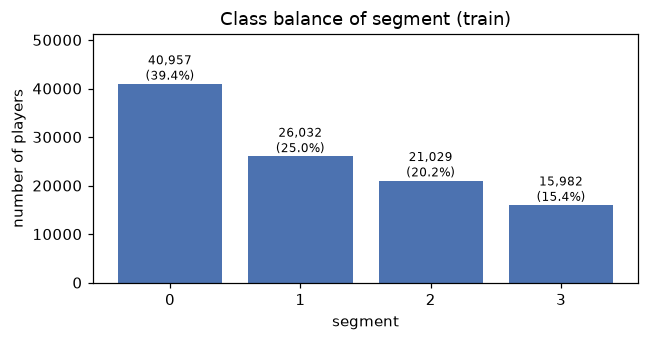

In [3]:
counts = pd.Series(y).value_counts().sort_index()
display(pd.DataFrame({'count': counts, 'share': (counts / counts.sum()).round(3)}).rename_axis('segment').T)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(counts.index.astype(str), counts.values, color='#4C72B0')
for i, v in enumerate(counts.values):
    ax.text(i, v, f'{v:,}\n({v / counts.sum():.1%})', ha='center', va='bottom', fontsize=8)
ax.set_title('Class balance of segment (train)')
ax.set_xlabel('segment')
ax.set_ylabel('number of players')
ax.set_ylim(0, counts.max() * 1.25)
plt.tight_layout()
plt.show()

### โครงสร้างของคลาส: สองปัจจัยแบบเกือบไบนารี

เมื่อดูค่าเฉลี่ยของแต่ละฟีเจอร์ในแต่ละคลาส (ปรับเป็นหน่วยของส่วนเบี่ยงเบนมาตรฐาน) พบว่าฟีเจอร์แบ่งเป็นสองกลุ่มชัดเจน
กลุ่มการใช้จ่าย (เช่น `total_spending_thb`, `vip_tier`, `rare_items_count`) แยกคลาส {0,1} ออกจาก {2,3}
ส่วนกลุ่มการมีส่วนร่วม (เช่น `play_frequency`, `friend_count`, `chat_activity_score`) แยกคลาส {0,2} ออกจาก {1,3}
ฟีเจอร์ข้อความก็มีรูปแบบเดียวกัน คือ `loyalty_tier` แยก {0,1} กับ {2,3} และ `engagement_level` แยก {0,2} กับ {1,3}

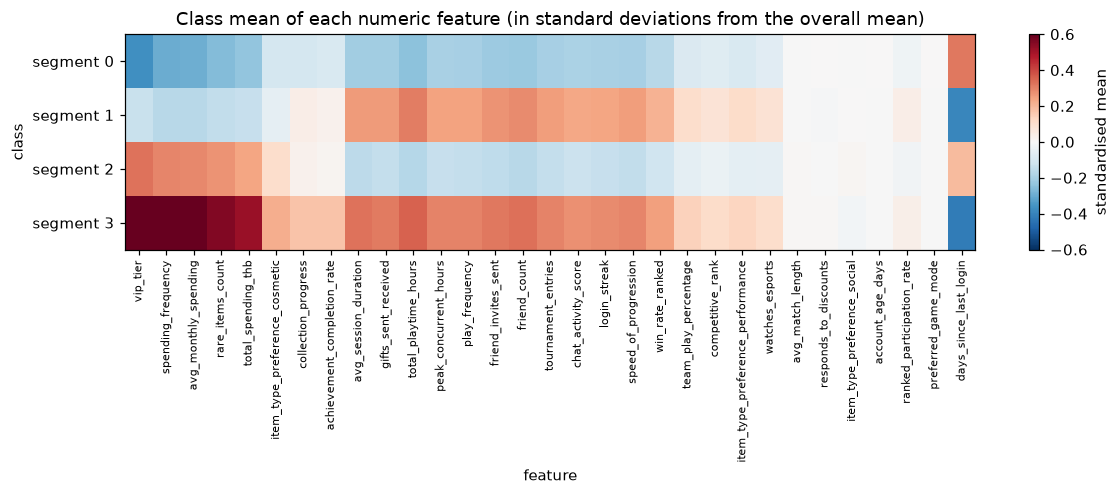

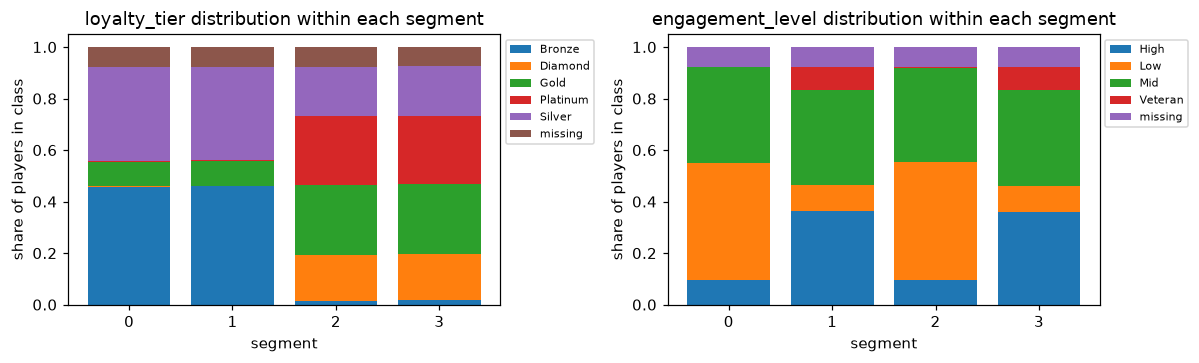

In [4]:
std_means = (train.groupby(TARGET)[num_cols].mean() - train[num_cols].mean()) / train[num_cols].std()
order = std_means.loc[[2, 3]].mean().sub(std_means.loc[[0, 1]].mean()).sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(11, 4.6))
im = ax.imshow(std_means[order].values, cmap='RdBu_r', vmin=-0.6, vmax=0.6, aspect='auto')
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=90, fontsize=7)
ax.set_yticks(range(4))
ax.set_yticklabels([f'segment {k}' for k in range(4)])
ax.set_title('Class mean of each numeric feature (in standard deviations from the overall mean)')
ax.set_xlabel('feature')
ax.set_ylabel('class')
fig.colorbar(im, ax=ax, label='standardised mean')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, col in zip(axes, ['loyalty_tier', 'engagement_level']):
    tab = pd.crosstab(train[col].fillna('missing'), y, normalize='columns')
    bottom = np.zeros(4)
    for lvl in tab.index:
        ax.bar(range(4), tab.loc[lvl].values, bottom=bottom, label=lvl)
        bottom += tab.loc[lvl].values
    ax.set_xticks(range(4))
    ax.set_title(f'{col} distribution within each segment')
    ax.set_xlabel('segment')
    ax.set_ylabel('share of players in class')
    ax.legend(fontsize=7, loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

### ภายในคลาสเดียวกัน ฟีเจอร์แทบไม่สัมพันธ์กัน

สหสัมพันธ์ระหว่างฟีเจอร์เมื่อดูทั้งชุดข้อมูลมีค่าพอสมควร แต่เมื่อแยกดูภายในแต่ละคลาส ค่าสหสัมพันธ์เกือบเป็นศูนย์ทั้งหมด
แปลว่าสหสัมพันธ์ที่เห็นในภาพรวมเกิดจากความต่างของค่าเฉลี่ยระหว่างคลาสเท่านั้น และเมื่อรู้คลาสแล้ว ฟีเจอร์เกือบเป็นอิสระต่อกัน
ซึ่งตรงกับสมมติฐานของ naive Bayes พอดี จึงคาดได้ว่า naive Bayes ที่ประมาณ density รายฟีเจอร์อย่างละเอียดจะทำงานได้ดีมากในโจทย์นี้

,mean |r|,max |r|
rows used,,
all classes together,0.0250,0.1534
within segment 0,0.0046,0.0169
within segment 1,0.0053,0.0230
within segment 2,0.0068,0.0239
within segment 3,0.0098,0.0401


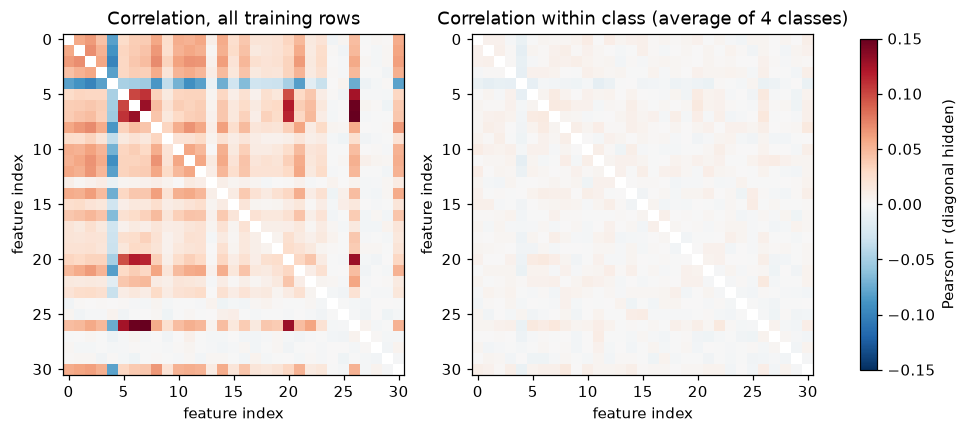

In [5]:
off = ~np.eye(len(num_cols), dtype=bool)
corr_all = train[num_cols].corr().values
corr_in = [train.loc[y == k, num_cols].corr().values for k in range(4)]
rows = [('all classes together', np.abs(corr_all[off]).mean(), np.abs(corr_all[off]).max())]
rows += [(f'within segment {k}', np.abs(c[off]).mean(), np.abs(c[off]).max()) for k, c in enumerate(corr_in)]
display(pd.DataFrame(rows, columns=['rows used', 'mean |r|', 'max |r|']).set_index('rows used'))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, mat, title in [(axes[0], corr_all, 'Correlation, all training rows'),
                       (axes[1], np.mean(corr_in, 0), 'Correlation within class (average of 4 classes)')]:
    im = ax.imshow(np.where(off, mat, np.nan), cmap='RdBu_r', vmin=-0.15, vmax=0.15)
    ax.set_title(title)
    ax.set_xlabel('feature index')
    ax.set_ylabel('feature index')
fig.colorbar(im, ax=axes, label='Pearson r (diagonal hidden)', shrink=0.85)
plt.show()

## การเตรียมข้อมูลและฟีเจอร์

**สำหรับ GBDT** ใช้ทุกคอลัมน์ยกเว้น `player_id`, `segment` และ `random_metric_*` (เป็น noise ล้วน) แล้วเพิ่มฟีเจอร์ดังนี้

- `n_missing` จำนวนค่าที่หายไปในแถว (คำนวณจากแถวเดียว)
- `spend_per_hour = total_spending_thb / (total_playtime_hours + 1)` และ `monthly_x_freq = avg_monthly_spending * spending_frequency`
- `social_sum` และ `comp_sum` ผลรวมของ percentile rank ของฟีเจอร์ด้านสังคม 4 ตัว และด้านการแข่งขัน 3 ตัว โดย rank วัดเทียบกับการกระจายของข้อมูล train เท่านั้น
  ฟีเจอร์ผลรวมช่วยรวมสัญญาณอ่อน ๆ หลายตัวในกลุ่มเดียวกันให้เป็นสัญญาณที่ชัดขึ้น ซึ่ง tree แบ่งทีละฟีเจอร์ทำได้ยาก
- คอลัมน์ข้อความแปลงเป็น pandas `category` โดยใช้ levels จาก train (ค่าใน test ที่ไม่เคยเห็นจะกลายเป็น missing)

**สำหรับ MLP** ใช้คอลัมน์ตัวเลขเดิม (ไม่ใช้ฟีเจอร์ที่สร้างเพิ่ม) เติม missing ด้วย median และแปลงด้วย `QuantileTransformer` (output แบบ normal) โดย fit บน training fold ของแต่ละ fold
ร่วมกับ one-hot ของคอลัมน์ข้อความ (levels จาก train), missing flag ของคอลัมน์ตัวเลขที่มี missing ใน train และจำนวน missing หาร 10

In [6]:
X, X_test, cats = gbdt_features(train, test)
new_cols = ['n_missing', 'spend_per_hour', 'monthly_x_freq', 'social_sum', 'comp_sum']
print('GBDT features:', X.shape[1], '| categorical:', cats)
display(X[new_cols].describe().T[['mean', 'std', 'min', '50%', 'max']])

NUM, ONE, nn_nums, nn_cats = nn_matrices(train, test)
print('MLP inputs: numeric', NUM.shape[1], '+ one-hot / missing block', ONE.shape[1], '=', NUM.shape[1] + ONE.shape[1])

folds = make_folds(y, SEED)
print('fold sizes (validation):', [len(va) for _, va in folds])

GBDT features: 46 | categorical: ['region', 'platform', 'device_type', 'payment_method', 'language', 'account_status', 'player_type_tag', 'engagement_level', 'loyalty_tier', 'skill_tier']


,mean,std,min,50%,max
n_missing,3.5678,1.7844,0.0000,3.0000,13.0000
spend_per_hour,34.9580,54.5105,0.1382,19.5593,1158.1240
monthly_x_freq,58506.2039,53955.0394,112.8757,42812.2827,511891.4434
social_sum,1.8557,0.6520,0.0000,1.8409,3.8967
comp_sum,1.4464,0.5393,0.0000,1.4468,2.9908


MLP inputs: numeric 31 + one-hot / missing block 72 = 103
fold sizes (validation): [20800, 20800, 20800, 20800, 20800]


## โมเดล

### GBDT 3 ตัว

hyperparameters คงที่ตามที่ใช้ในการส่งจริง ทุกตัวใช้ early stopping 200 รอบบน validation fold

| โมเดล | การตั้งค่าหลัก |
|---|---|
| LightGBM | multiclass, learning_rate 0.03, num_leaves 63, min_child_samples 40, subsample 0.8, colsample_bytree 0.6, reg_lambda 1 |
| XGBoost | multi:softprob, eta 0.03, max_depth 7, min_child_weight 5, subsample 0.8, colsample_bytree 0.6, hist, max_cat_to_onehot 8 |
| CatBoost | MultiClass, learning_rate 0.05, depth 7, od_wait 200, คอลัมน์ข้อความเป็น cat_features |

ส่วนนี้ใช้เวลานานที่สุดของ notebook (CatBoost ใช้เวลามากที่สุด) ผลของ XGBoost แบบ `hist` เปลี่ยนเล็กน้อยตามจำนวน thread จึงกำหนด 16 threads ให้ตรงกับรอบที่ส่งจริง

In [7]:
gbdt = {}
rows = []
for name in ['lgb', 'xgb', 'cat']:
    oof, tp, info = run_gbdt_cv(name, X, y, X_test, cats, folds)
    gbdt[name] = (oof, tp)
    rows.append((name, f1_score(y, oof.argmax(1), average='macro'), info['iters'], round(info['minutes'], 1)))
gbdt_table = pd.DataFrame(rows, columns=['model', 'OOF macro F1', 'best iteration per fold', 'minutes']).set_index('model')
gbdt_table

,OOF macro F1,best iteration per fold,minutes
model,,,
lgb,0.7519,"[407, 374, 469, 458, 437]",2.1
xgb,0.7517,"[728, 717, 687, 751, 721]",4.9
cat,0.7521,"[1322, 1121, 1244, 1321, 1126]",68.7


### MLP (PyTorch)

MLP ขนาด 512-256-128 ใช้ SiLU, BatchNorm และ dropout 0.25 ฝึกด้วย AdamW (lr 2e-3, weight decay 1e-4), cross-entropy แบบ label smoothing 0.05,
batch 512, ลด learning rate เมื่อ validation loss ไม่ดีขึ้น และหยุดเมื่อไม่ดีขึ้น 6 epoch ติดกัน
แต่ละ fold ฝึก 3 seeds (seed = 100 * fold + s) แล้วเฉลี่ย MLP เป็นโมเดลอีกแบบที่มี inductive bias ต่างจาก tree จึงช่วยเสริมกันเมื่อนำมาผสม

In [8]:
nn_oof, nn_test, nn_info = run_nn_cv(NUM, ONE, y, folds, n_seeds=3, threads=NN_THREADS)
print(f"MLP x3 seeds: OOF macro F1 {f1_score(y, nn_oof.argmax(1), average='macro'):.4f}"
      f"  ({nn_info['minutes']:.1f} min, epochs per run {min(nn_info['epochs'])}-{max(nn_info['epochs'])})")

MLP x3 seeds: OOF macro F1 0.7514  (13.0 min, epochs per run 11-17)


## การรวมโมเดล

### ค่าเฉลี่ย GBDT และน้ำหนักของ MLP

เฉลี่ยความน่าจะเป็นของ GBDT ทั้ง 3 ตัวเท่า ๆ กัน (`blend`) แล้วผสมกับ MLP แบบเส้นตรง `blendnn = (1 - a) * blend + a * nn`
โดยลองค่า a ตั้งแต่ 0 ถึง 1 ทีละ 0.1 และเลือกค่าที่ให้ OOF macro F1 สูงสุด

GBDT mean: 0.7537  ->  with MLP weight 0.3: 0.7551


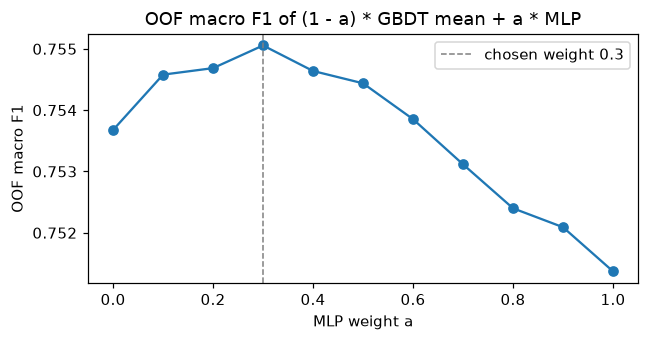

In [9]:
blend_oof = np.mean([gbdt[m][0] for m in ['lgb', 'xgb', 'cat']], 0)
blend_test = np.mean([gbdt[m][1] for m in ['lgb', 'xgb', 'cat']], 0)

nn_grid = np.round(np.arange(0, 1.01, 0.1), 1)
nn_scores = [f1_score(y, ((1 - a) * blend_oof + a * nn_oof).argmax(1), average='macro') for a in nn_grid]
best_score, NN_WEIGHT = max(zip(nn_scores, nn_grid))
blendnn_oof = (1 - NN_WEIGHT) * blend_oof + NN_WEIGHT * nn_oof
blendnn_test = (1 - NN_WEIGHT) * blend_test + NN_WEIGHT * nn_test
print(f'GBDT mean: {nn_scores[0]:.4f}  ->  with MLP weight {NN_WEIGHT}: {best_score:.4f}')

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(nn_grid, nn_scores, marker='o')
ax.axvline(NN_WEIGHT, color='grey', ls='--', lw=1, label=f'chosen weight {NN_WEIGHT}')
ax.set_title('OOF macro F1 of (1 - a) * GBDT mean + a * MLP')
ax.set_xlabel('MLP weight a')
ax.set_ylabel('OOF macro F1')
ax.legend()
plt.tight_layout()
plt.show()

### Naive Bayes พร้อมโมเดล label noise (EM)

จากผลการสำรวจข้อมูลที่ว่าฟีเจอร์เป็นอิสระต่อกันเมื่อรู้คลาส จึงสร้าง naive Bayes ที่ประมาณ density ของแต่ละฟีเจอร์แยกตามคลาสอย่างละเอียด

- คอลัมน์ตัวเลขต่อเนื่อง: แบ่งเป็น 100 bins แบบ equal-mass (edges จาก training fold) และทำให้ histogram เรียบด้วย Gaussian filter (sigma 2.5 bins)
  ค่าที่ซ้ำบ่อยมาก เช่น ค่าที่ถูก clip ที่ขอบ จะแยกเป็น atom ของตัวเอง ส่วนคอลัมน์ที่มีค่าต่างกันไม่เกิน 25 ค่าและคอลัมน์ข้อความใช้หนึ่ง level ต่อค่า
- missing ไม่ถูกนับในความน่าจะเป็น (ข้ามไปเฉย ๆ)
- ตัดคอลัมน์ที่ไม่มีข้อมูลเกี่ยวกับคลาส (`random_metric_*` และคอลัมน์ที่การกระจายเหมือนกันทุกคลาส เช่น `region`, `platform`, `skill_tier`) เพื่อลด noise
- โมเดล label noise: มองว่า label ที่เห็นเป็นสำเนาที่มี noise ของคลาสจริง ผ่าน transition matrix T ขนาด 4x4
  ใช้ EM 8 รอบ สลับระหว่างคำนวณ posterior ของคลาสจริงกับ fit density และ T ใหม่ แล้วทำนาย `p @ T` ซึ่งคือความน่าจะเป็นของ label ที่สังเกตได้

แต่ละ fold fit NB2 ใหม่บน training fold เท่านั้น การทำนาย test ใช้ค่าเฉลี่ยเรขาคณิตของ 5 fold
ภาพ transition matrix ด้านล่างแสดงว่าโมเดลประเมินให้ label สลับไปยังคลาสอื่นแต่ละคลาสประมาณ 1% อย่างสม่ำเสมอ ซึ่งเป็นลักษณะของ noise แบบสุ่มที่ไม่มีโมเดลใดแก้ได้

EM naive Bayes (28 features): OOF macro F1 0.7538  (0.4 min)
estimated share of noisy labels: 2.73%


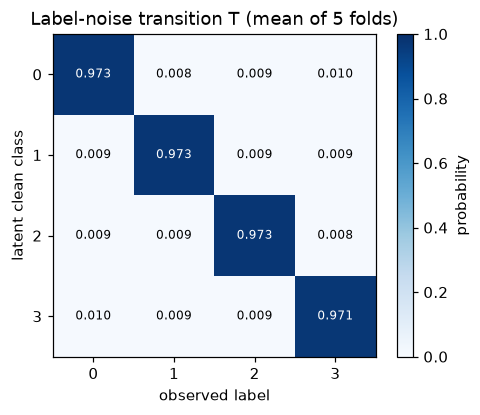

In [10]:
nb_cols = nb_features(train)
t0 = time.time()
nb_oof, nb_test, nb_models = run_nb_cv(train, y, test, nb_cols, folds, nbins=100, smooth=2.5, em=8, alpha=0.5)
print(f"EM naive Bayes ({len(nb_cols)} features): OOF macro F1 {macro_f1(y, nb_oof.argmax(1)):.4f}  ({(time.time() - t0) / 60:.1f} min)")

T_mean = np.mean([m.T for m in nb_models], 0)
pi_mean = np.mean([m.pi for m in nb_models], 0)
noise = 1 - (pi_mean * np.diag(T_mean)).sum()
print(f'estimated share of noisy labels: {noise:.2%}')

fig, ax = plt.subplots(figsize=(4.6, 3.8))
im = ax.imshow(T_mean, cmap='Blues', vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{T_mean[i, j]:.3f}', ha='center', va='center', fontsize=8,
                color='white' if T_mean[i, j] > 0.5 else 'black')
ax.set_xticks(range(4))
ax.set_yticks(range(4))
ax.set_title('Label-noise transition T (mean of 5 folds)')
ax.set_xlabel('observed label')
ax.set_ylabel('latent clean class')
fig.colorbar(im, ax=ax, label='probability')
plt.tight_layout()
plt.show()

### Log-mix ระหว่าง blendnn กับ naive Bayes

รวมสองแหล่งด้วยค่าเฉลี่ยเรขาคณิตถ่วงน้ำหนัก `z = (1 - a) log(blendnn) + a log(nb)` แล้ว normalize ด้วย softmax
การรวมใน log space เหมาะกับ naive Bayes เพราะผลลัพธ์ของ NB เป็นผลคูณของ likelihood อยู่แล้ว
น้ำหนัก a เลือกด้วย nested CV ซึ่งวัดคะแนนหลังปรับน้ำหนักรายคลาสแบบที่น้ำหนักของแต่ละ fold เรียนจากอีก 4 fold เท่านั้น
ค่าที่ใช้ในการส่งจริงคือ `A_MIX = 0.4` ซึ่งเลือกจากการเปรียบเทียบ a = 0.3, 0.4, 0.5 ด้วย nested CV ตารางและกราฟด้านล่างแสดงช่วงค่าที่กว้างขึ้น
จะเห็นว่าทุกค่า a ตั้งแต่ 0.3 ถึง 0.8 ให้คะแนนต่างกันไม่เกินประมาณ 0.0005 ซึ่งเป็นความต่างระดับเดียวกับความไม่แน่นอนของการประเมินด้วย OOF
สิ่งที่สำคัญคือการเพิ่ม NB เข้าไป (a > 0) ดีกว่าไม่ใช้ NB อย่างสม่ำเสมอ ส่วนค่า a ที่แน่นอนในช่วงนี้แทบไม่มีผล

a (NB weight),0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8
raw OOF macro F1,0.7551,0.7556,0.7562,0.7563,0.7560,0.756,0.7558,0.7556,0.7554
nested macro F1 (class weights),0.7554,0.7555,0.7557,0.7562,0.7562,0.756,0.7563,0.7558,0.7561


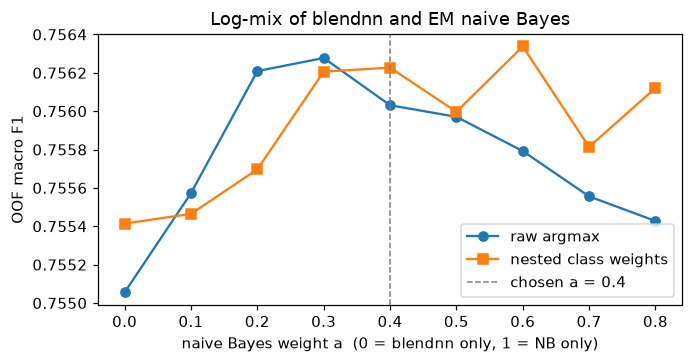

In [11]:
A_MIX = 0.4
mix_grid = np.round(np.arange(0, 0.81, 0.1), 1)
rows = []
for a in mix_grid:
    p = log_mix(blendnn_oof, nb_oof, a)
    rows.append((a, macro_f1(y, p.argmax(1)), macro_f1(y, nested_weighted_labels(y, p, folds))))
mix_table = pd.DataFrame(rows, columns=['a (NB weight)', 'raw OOF macro F1', 'nested macro F1 (class weights)'])
display(mix_table.set_index('a (NB weight)').T)

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(mix_table.iloc[:, 0], mix_table.iloc[:, 1], marker='o', label='raw argmax')
ax.plot(mix_table.iloc[:, 0], mix_table.iloc[:, 2], marker='s', label='nested class weights')
ax.axvline(A_MIX, color='grey', ls='--', lw=1, label=f'chosen a = {A_MIX}')
ax.set_title('Log-mix of blendnn and EM naive Bayes')
ax.set_xlabel('naive Bayes weight a  (0 = blendnn only, 1 = NB only)')
ax.set_ylabel('OOF macro F1')
ax.legend()
plt.tight_layout()
plt.show()

final_oof = log_mix(blendnn_oof, nb_oof, A_MIX)
final_test = log_mix(blendnn_test, nb_test, A_MIX)

### ปรับน้ำหนักรายคลาส (decision weights)

เพราะ macro F1 ให้ความสำคัญกับทุกคลาสเท่ากัน การเลือกคลาสด้วย `argmax(p * w)` แทน `argmax(p)` จะช่วยเลื่อนเส้นแบ่งระหว่างคลาสให้เหมาะกับ metric
น้ำหนัก w หาด้วย coordinate search บน OOF (ค่า 0.50 ถึง 2.45 ทีละ 0.05, 3 รอบ, กำหนด w[3] = 1) แล้วใช้ w ชุดเดียวกันกับ test
คะแนน in-sample หลังปรับน้ำหนักจะสูงเกินจริงเล็กน้อย จึงรายงานคะแนน nested ไว้คู่กัน

In [12]:
W_CLASS = fit_class_weights(y, final_oof)
final_oof_label = (final_oof * W_CLASS).argmax(1)
final_nested = nested_weighted_labels(y, final_oof, folds)
print('class weights w =', np.round(W_CLASS, 2))
print(f'final OOF macro F1: raw {macro_f1(y, final_oof.argmax(1)):.4f} | with w (in-sample) {macro_f1(y, final_oof_label):.4f}'
      f' | nested {macro_f1(y, final_nested):.4f}')

class weights w = [0.75 0.95 0.9  1.  ]
final OOF macro F1: raw 0.7560 | with w (in-sample) 0.7573 | nested 0.7562


## การตรวจสอบด้วย Cross-validation

ตารางสรุปคะแนน OOF macro F1 ของทุกขั้นตอน (raw คือ argmax ของความน่าจะเป็น) และ confusion matrix ของคำทำนาย OOF สุดท้าย

,OOF macro F1
step,
LightGBM,0.7519
XGBoost,0.7517
CatBoost,0.7521
MLP (3 seeds),0.7514
blend = mean of 3 GBDTs,0.7537
blendnn = 0.7 blend + 0.3 MLP,0.7551
EM naive Bayes,0.7538
log-mix a = 0.4 (raw),0.7560
log-mix + class weights (in-sample),0.7573


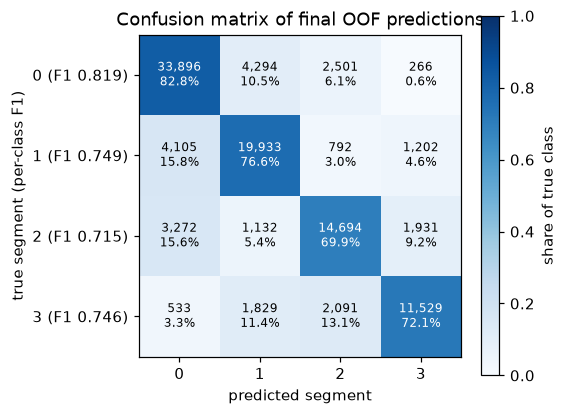

In [13]:
summary = pd.DataFrame([
    ('LightGBM', macro_f1(y, gbdt['lgb'][0].argmax(1))),
    ('XGBoost', macro_f1(y, gbdt['xgb'][0].argmax(1))),
    ('CatBoost', macro_f1(y, gbdt['cat'][0].argmax(1))),
    ('MLP (3 seeds)', macro_f1(y, nn_oof.argmax(1))),
    ('blend = mean of 3 GBDTs', macro_f1(y, blend_oof.argmax(1))),
    (f'blendnn = {1 - NN_WEIGHT:.1f} blend + {NN_WEIGHT:.1f} MLP', macro_f1(y, blendnn_oof.argmax(1))),
    ('EM naive Bayes', macro_f1(y, nb_oof.argmax(1))),
    (f'log-mix a = {A_MIX} (raw)', macro_f1(y, final_oof.argmax(1))),
    ('log-mix + class weights (in-sample)', macro_f1(y, final_oof_label)),
    ('log-mix + class weights (nested)', macro_f1(y, final_nested)),
], columns=['step', 'OOF macro F1']).set_index('step')
display(summary)

cm = confusion_matrix(y, final_oof_label)
cm_norm = cm / cm.sum(1, keepdims=True)
per_class_f1 = f1_score(y, final_oof_label, average=None)
fig, ax = plt.subplots(figsize=(5.2, 4.2))
im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{cm[i, j]:,}\n{cm_norm[i, j]:.1%}', ha='center', va='center', fontsize=8,
                color='white' if cm_norm[i, j] > 0.5 else 'black')
ax.set_xticks(range(4))
ax.set_yticks(range(4))
ax.set_yticklabels([f'{k} (F1 {f:.3f})' for k, f in enumerate(per_class_f1)])
ax.set_title('Confusion matrix of final OOF predictions')
ax.set_xlabel('predicted segment')
ax.set_ylabel('true segment (per-class F1)')
fig.colorbar(im, ax=ax, label='share of true class')
plt.tight_layout()
plt.show()

## การสร้างไฟล์คำตอบ

ใช้ความน่าจะเป็นของ test จาก log-mix คูณน้ำหนักรายคลาสที่เรียนจาก OOF แล้วเลือกคลาสที่มีค่าสูงสุด
`id` คือ `ANS` ตามด้วยลำดับแถวของ test (เริ่มที่ 1) แบบ 5 หลัก

In [14]:
test_label = (final_test * W_CLASS).argmax(1)
sub = pd.DataFrame({'id': [f'ANS{i + 1:05d}' for i in range(len(test))], 'task2': test_label})
assert len(sub) == len(test) and sub['id'].is_unique
sub.to_csv(OUT_DIR / 'task2_pred.csv', index=False)

dist = pd.DataFrame({'test predicted share': sub['task2'].value_counts(normalize=True).sort_index(),
                     'train share': pd.Series(y).value_counts(normalize=True).sort_index()}).rename_axis('segment')
print(f'saved output/task2_pred.csv  ({len(sub):,} rows)   total notebook time {(time.time() - T_START) / 60:.0f} min')
display(dist.round(3).T)

saved output/task2_pred.csv  (25,889 rows)   total notebook time 91 min


segment,0,1,2,3
test predicted share,0.405,0.262,0.190,0.143
train share,0.394,0.250,0.202,0.154


## สรุป

- ข้อมูลมีโครงสร้างแบบสองปัจจัย (การใช้จ่าย และการมีส่วนร่วม) และฟีเจอร์แทบเป็นอิสระต่อกันเมื่อรู้คลาส naive Bayes ที่ประมาณ density รายฟีเจอร์อย่างละเอียด
  จึงทำคะแนนได้เท่ากับหรือดีกว่า GBDT แต่ละตัวเล็กน้อย ทั้งที่เป็นโมเดลที่เรียบง่ายกว่ามาก
- GBDT 3 ตัวได้คะแนนใกล้กันมาก (ประมาณ 0.752) การเฉลี่ยและผสม MLP ช่วยเพิ่มได้เล็กน้อย และการ log-mix กับ naive Bayes ให้ผลดีที่สุด
  เพราะสองแหล่งทำผิดพลาดต่างกัน การปรับน้ำหนักรายคลาสช่วยให้เส้นแบ่งเหมาะกับ macro F1 มากขึ้น
- คะแนนของทุกวิธีกระจุกกันในช่วงแคบมาก (ประมาณ 0.751 ถึง 0.757) ซึ่งบ่งว่าเราเข้าใกล้ขีดจำกัดที่ noise ของข้อมูลกำหนดไว้แล้ว
  คลาสต่าง ๆ ซ้อนทับกันจริงในปริภูมิฟีเจอร์ และโมเดล label noise ประเมินว่า label ของแต่ละคลาสถูกสลับไปเป็นคลาสอื่นคลาสละประมาณ 1% อย่างสม่ำเสมอ
  (รวมประมาณ 2.7% ของแถว) การปรับปรุงเพิ่มจึงทำได้เพียงเล็กน้อย